<a href="https://colab.research.google.com/github/hyui02/ESAA_assignment/blob/main/ESAA_WEEK13_%EC%88%98%EC%83%81%EC%9E%91%EB%A6%AC%EB%B7%B0_%EB%AC%BC%EA%B0%80%EC%98%88%EC%B8%A1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 수상작 리뷰: 데이터·AI를 활용한 물가 예측 경진대회 – 농산물 가격을 중심으로 (본선 대상)

- 리뷰 자료: [쥬혁이_외부 변동성 반영 AI 모델 개발 및 실제 활용 전략](https://dacon.io/competitions/official/236417/codeshare/12096) (팀 쥬혁이 본선 발표 자료, PDF 58쪽)
- 대회: [데이터·AI를 활용한 물가 예측 경진대회 (DACON, 2024)](https://dacon.io/competitions/official/236381/overview/description) / [본선 페이지](https://dacon.io/competitions/official/236417/overview/description)
- 결과: 본선 10팀 중 **대상(1위)**. 본선 순위는 예측 정확도 50%와 발표 점수 50%를 합산해 정했으며, 이 팀의 예측 정확도는 89.9%였다(본선 진출팀 평균 89.2%).
- 한 줄 요약: 농산물 가격에 영향을 주는 요인을 **자연적·시계열·경제적·외부 개입** 네 가지로 나누어 파생변수를 만들고, 시계열 딥러닝(DLinear + 어텐션)의 예측값을 머신러닝(LightGBM)의 입력으로 넣는 **TIME ML** 방식과 예측 시점별 가중 앙상블로 T+1~3순 가격을 예측하였다. 이어서 이 모델로 **정부의 수매·방출 시점과 물량을 정하는 의사결정 시스템**을 제안하였다.

> **이번 리뷰의 특징**: 리뷰 대상이 코드가 아니라 **발표 자료(PPT)** 이다. 작성자는 발표 평가 항목에 맞추기 위해 검증 방법과 세부 방법론을 PPT에서 뺐다고 밝혔다. 따라서 3장의 코드는 원본 코드가 아니라, **PPT에 설명된 기법을 작은 예시 데이터로 직접 재구성한 것**이다. 원본과 세부 구현(하이퍼파라미터, 임계값 등)은 다를 수 있다.

---

# **1. 데이터 설명**

## 1-1. 대회 과제
- 국민 생활과 밀접한 **10개 농산물**(배추, 무, 양파, 사과, 배, 건고추, 깐마늘, 감자, 대파, 상추)의 지정된 품종·등급에 대해 **평균 가격(원)** 을 예측하는 시계열 회귀 문제이다.
- 데이터는 **순(旬) 단위**(한 달을 상순·중순·하순으로 나눈 약 10일 단위)로 주어진다. 1년은 36순이다.
- 추론 시점 T를 기준으로 **최대 3개월(9개 순)의 입력 데이터**만 보고 **T+1순, T+2순, T+3순**의 평균 가격을 예측한다.
- 평가지표는 **NMAE(Normalized Mean Absolute Error)** 이다. 오차의 절댓값을 실제값으로 나눈 비율의 평균으로, 가격 수준이 다른 품목(예: 건고추와 상추)을 같은 기준으로 비교할 수 있다.

$$\text{NMAE} = \frac{1}{n}\sum_{i=1}^{n}\frac{|y_i-\hat{y}_i|}{|y_i|}$$

## 1-2. 대회 진행 방식
| 단계 | 기간 | 내용 |
|---|---|---|
| 1차 예선 | 2024.10.01 ~ 10.14 | Private 리더보드 상위 20팀이 2차 예선 진출 (1,904명 참가) |
| 2차 예선 | 2024.10.18 ~ 10.29 | 별도 대회 페이지에서 **추가 데이터**를 제공. Private 점수와 추가 평가 점수 합산 상위 10팀이 본선 진출 |
| 본선 | 2024.11.14 | 결과보고서와 발표 자료 제출 후 **오프라인 발표 평가**(2024 대한민국 정부 박람회 프로그램) |

- 학습 데이터 기간은 단계마다 다르다. 1차 예선은 2018~2021년 학습, 2022년 평가였고, PPT에 적힌 2차 예선 기준은 **2018~2022년 학습, 2023~2024년 평가**이다.
- 평가 데이터의 추론 시점 T는 **비식별화**되어 있어 정확한 날짜를 알 수 없다.

## 1-3. 파일 구성 (1차 예선 기준)
| 구분 | 파일 | 내용 |
|---|---|---|
| 학습 | `train/train.csv` | 2018~2021년 모든 농산물의 상세 정보와 가격 |
| | `train/meta/TRAIN_전국도매_2018-2021.csv`, `TRAIN_산지공판장_2018-2021.csv` | 전국 도매시장과 산지공판장의 경락(경매 낙찰) 정보 |
| 평가 | `test/TEST_00.csv` ~ `TEST_24.csv` | 시점 T를 포함한 최대 3개월(9개 시점) 입력 데이터. 총 25개 샘플 |
| | `test/meta/TEST_전국도매_00~24.csv`, `TEST_산지공판장_00~24.csv` | 각 평가 샘플에 대응하는 경락 정보 |
| 제출 | `sample_submission.csv` | 샘플별 +1순, +2순, +3순의 품목별 평균 가격 |

## 1-4. 데이터를 다룰 때 알아 둘 규칙과 특징
- **평가 샘플 간 교차 활용 금지**: `TEST_00`을 추론할 때는 `TEST_00.csv`와 그에 대응하는 meta 파일만 쓸 수 있다. 다른 평가 샘플을 이어 붙여 정답을 유추하면 실격이다.
- **입력 길이 제한**: 한 샘플의 입력은 최대 9개 순뿐이다. 이 팀이 EDA에서 가장 크게 다룬 제약이 바로 이것이다(2-1 참고).
- **외부 데이터**: 1차 예선 규칙에서는 외부 데이터 사용이 금지되어 있었다. PPT에는 유가, 기상, 수출입량 같은 변수가 등장하는데, 이것이 2차 예선의 추가 제공 데이터인지는 PPT만으로 확인할 수 없다.
- **품목마다 성격이 다르다**: 배추·무처럼 계절에 따라 크게 출렁이는 품목과 깐마늘·건고추처럼 저장성이 높아 완만하게 움직이는 품목이 섞여 있다. 이 팀은 이 차이를 Hurst 지수로 나누어 품목별로 다른 모델을 썼다(3-⑥).

---

# **2. 분석 흐름**

PPT는 **INTRO → EDA → 모델링 → 모델 활용** 순서로 구성되어 있다. 코드 대신 발표 흐름을 단계별로 정리하였다.

1. **EDA: 가격 형성 요인을 네 가지로 분류**
    - **자연적 요인**(기온, 강수량, 일조, 습도 등): 2020년 태풍 하이선 이후 2021년 2월 대파 가격이 급등한 사례를 들어, 3개월 입력 제한 때문에 그보다 앞선 기상 충격을 모델이 볼 수 없다는 점을 지적한다. 기상 값을 그대로 쓰지 않고 **누적값**으로 바꾼다.
    - **시계열 요인**(추세, 계절성, 주기성): 추세는 이동평균보다 지연이 적은 **저역통과필터(LPF)** 로 뽑는다. 계절성은 sin/cos 변환, 수확 시기 가중치, 평균·표준편차 인코딩으로, 주기성은 누적 증감과 차분 변수로 반영한다.
    - **경제적 요인**(유가, 총반입량 등): **그랜저 인과 검정**과 **충격 반응 함수**로 가격보다 먼저 움직이는 선행 변수인지 검정한 뒤 사용한다. 유가는 가격을 올리는 방향, 총반입량은 내리는 방향으로 반응하였다.
    - **외부 개입**(정부의 수매·방출): 데이터에 직접 기록되지 않아 AI가 학습할 수 없다고 보고, **가격 변화율에 따른 개입 확률**, **비축 물량 방출 가능성** 같은 규칙 기반 파생변수를 만든다. 2022년 9월 중순 배추 방출 시점과 이 값이 높아지는 시점이 일치함을 보였다. 농산물 수급관리 가이드라인의 위기 단계 기준가격도 피처로 보완한다.
2. **모델링**
    - **Hurst 지수**로 품목을 나눈다. 0.5보다 작은(평균 회귀적) 품목은 ML 모델, 0.5보다 큰(추세 지속적) 품목은 시계열 모델을 중심으로 쓴다. UMAP으로도 품목별 분포가 뚜렷이 나뉨을 확인하였다.
    - **시계열 모델**: 추세와 계절성을 분해해 각각 선형층에 넣는 **DLinear**를 쓴다(5년 데이터 학습 0.4초). 다만 배추처럼 계절적으로 급등하는 구간을 잘 따라가지 못해 **어텐션**을 추가하였다.
    - **ML 모델**: **LightGBM**(leaf-wise 성장, 히스토그램 방식).
    - **TIME ML**: 기존 ML은 1·2·3순을 서로 독립적으로 예측해 추세가 반영되지 않는다. 시계열 모델이 예측한 앞 순의 값을 ML의 입력에 추가하여 2순, 3순을 예측한다.
    - **앙상블**: 가까운 시점(T+1순)은 시계열 딥러닝에, 먼 시점(T+3순)은 ML에 더 큰 가중치를 둔다.
    - 12일 동안 360번 제출하며 실험했고, Fold와 시계열 모델의 마지막 학습 날짜에 따라 성능 차이가 크다는 점을 발견하였다.
3. **모델 활용: AI 기반 수매·방출 의사결정 시스템**
    - N순 예측 가격이 '심각' 구간에 들어가면, N-1순에 수매(가격 하락 시) 또는 방출(가격 상승 시)을 결정한다.
    - 물량이 가격에 미치는 **영향 계수**로 N-1순 가격을 조정하고, 조정된 가격을 다시 TIME ML에 넣어 N순을 재예측하는 **피드백 루프**로 최적 물량을 찾는다.
    - 최적화를 위한 수매·방출 **목적함수 초안**을 제시하고, 정부·농민·소비자별 기대효과와 선물 거래 시스템, 농산물 보험 같은 확장 활용 방안을 덧붙였다.

---

# **3. 주요 코드 분석**

- 원본 코드가 공개되지 않았으므로, PPT에 설명된 기법을 **작은 예시 데이터(순 단위 5년, 180개 시점)** 로 재구성하였다. 대회 데이터 없이 에러 없이 실행된다.
- 첫 코드 셀(라이브러리)과 두 번째 셀(예시 데이터)을 먼저 실행한 뒤 위에서부터 차례로 실행한다.
- 그래프의 글자는 Colab 기본 환경에서 한글이 깨지지 않도록 영어로 적었다.

In [1]:
import warnings, contextlib, io
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, lfilter
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.tsa.api import VAR
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
import lightgbm as lgb

np.random.seed(42)

def nmae(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean(np.abs(y_true - y_pred) / np.abs(y_true))

**예시 데이터 만들기**
- 배추와 비슷하게 움직이는 가상의 가격을 만든다. 가격에는 연간 계절성, 유가의 영향(3순 뒤에 반영), **최근 12순 동안의 누적 강수량**의 영향, 무작위 잡음을 넣었다.
- 실제 대회처럼 연·월·순 정보를 붙이고, 2018~2021년을 학습 구간, 2022년을 평가 구간으로 쓴다.

In [2]:
n = 36 * 5                                    # 순 단위 5년(2018~2022)
t = np.arange(n)

df = pd.DataFrame({'t': t})
df['year'] = 2018 + t // 36
df['month'] = (t % 36) // 3 + 1
df['xun'] = t % 3                             # 0=상순, 1=중순, 2=하순
df['xun_idx'] = t % 36                        # 1년 안에서 몇 번째 순인지(0~35)

# 강수량: 여름(7~8월)에 많고 가끔 태풍처럼 큰 값
season_rain = 20 + 60 * np.exp(-((df['xun_idx'] - 20) ** 2) / 20)
df['rain'] = np.random.gamma(2, season_rain / 2)
df.loc[[56, 128], 'rain'] += 250              # 태풍 같은 극단 이벤트 2번

# 유가: 랜덤워크
df['oil'] = 1500 + np.cumsum(np.random.normal(0, 15, n))

# 가격 = 기본값 + 계절성 + 유가(3순 뒤 반영) + 누적 강수(최근 12순) + 잡음
rain_cum12 = df['rain'].rolling(12, min_periods=1).sum()
df['price'] = (3000
               + 900 * np.sin(2 * np.pi * (df['xun_idx'] - 9) / 36)
               + 6.0 * (df['oil'].shift(3).bfill() - 1500)
               + 3.0 * (rain_cum12 - rain_cum12.mean())
               + np.random.normal(0, 80, n)).round()

train_mask = df['year'] <= 2021
df.head()

,t,year,month,xun,xun_idx,rain,oil,price
0,0,2018,1,0,0,23.936794,1508.206461,1110.0
1,1,2018,1,1,1,14.944648,1505.173571,1104.0
2,2,2018,1,2,2,13.822840,1501.908353,1115.0
3,3,2018,2,0,3,13.823045,1518.390006,1342.0
4,4,2018,2,1,4,46.497529,1530.771251,1441.0


**① 자연적 요인: 기상 변수를 누적값으로 바꾸기**

In [3]:
df['rain_cum_9'] = df['rain'].rolling(9, min_periods=1).sum()     # 최근 9순(3개월) 누적
df['rain_cum_12'] = df['rain'].rolling(12, min_periods=1).sum()   # 최근 12순(4개월) 누적

# 3순 뒤 가격과의 상관계수 비교
future_price = df['price'].shift(-3)
for col in ['rain', 'rain_cum_9', 'rain_cum_12']:
    print(f'{col:12s} vs 3순 뒤 가격 상관계수: {df[col].corr(future_price):.3f}')

rain         vs 3순 뒤 가격 상관계수: 0.522
rain_cum_9   vs 3순 뒤 가격 상관계수: 0.622
rain_cum_12  vs 3순 뒤 가격 상관계수: 0.446


- 그날그날의 강수량은 값이 크게 튀어 가격과의 관계가 잘 드러나지 않는다. 누적값으로 바꾸면 잡음이 줄고 **과거 기상 충격이 오래 남는 효과**가 표현되어 상관이 커진다.
- 다만 누적 기간을 얼마로 잡느냐에 따라 결과가 달라진다(위 예시에서도 9순과 12순의 상관계수가 다르다). 품목의 재배 기간에 맞춰 여러 길이를 시험해 보아야 한다.
- PPT는 이를 "먹이" 개념이라고 불렀다. 작물이 자라는 동안 받은 날씨가 쌓여서 나중의 출하량과 가격에 영향을 준다는 뜻이다. 대파 사례에서 태풍이 있었던 '중요 기간'은 입력 기간보다 앞에 있었는데, 누적값을 쓰면 그 영향이 입력 기간 안의 값에 남는다.
- 다만 평가 샘플의 입력은 9순뿐이므로, 9순보다 긴 누적값(예: 12순)을 추론 시점에 어떻게 계산했는지는 PPT에 나오지 않는다. 날짜를 기준으로 기상 데이터를 따로 붙일 수 있어야 가능하다.

**② 시계열 요인: 이동평균 vs 저역통과필터(LPF)로 추세 뽑기**

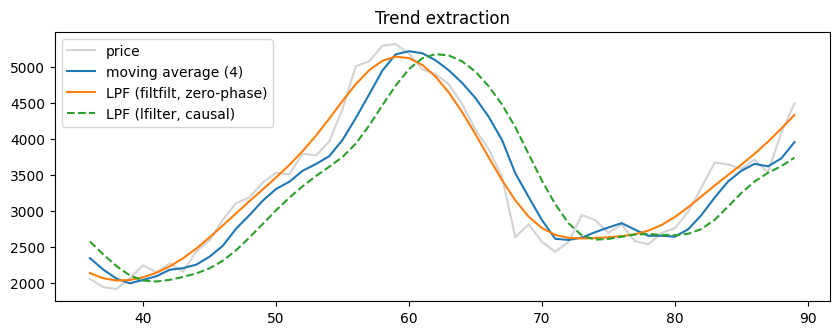

시점 100의 추세값  - 시점 100까지만 사용: 4541.1 / 전체 데이터 사용: 4283.1


In [4]:
b, a = butter(N=2, Wn=0.15)                    # 2차 버터워스 저역통과필터

df['trend_ma'] = df['price'].rolling(4, min_periods=1).mean()   # 과거 4순 이동평균
df['trend_lpf_zero'] = filtfilt(b, a, df['price'])               # 앞뒤로 두 번 거르는 필터(지연 0)
df['trend_lpf_causal'] = lfilter(b, a, df['price'] - df['price'].iloc[0]) + df['price'].iloc[0]  # 과거만 쓰는 필터

seg = df.iloc[36:90]
plt.figure(figsize=(10, 3.5))
plt.plot(seg['t'], seg['price'], color='lightgray', label='price')
plt.plot(seg['t'], seg['trend_ma'], label='moving average (4)')
plt.plot(seg['t'], seg['trend_lpf_zero'], label='LPF (filtfilt, zero-phase)')
plt.plot(seg['t'], seg['trend_lpf_causal'], '--', label='LPF (lfilter, causal)')
plt.legend(); plt.title('Trend extraction'); plt.show()

# filtfilt는 미래 값을 쓴다: 시점 100까지만 있을 때와 전체가 있을 때 시점 100의 추세값 비교
cut = 100
part = filtfilt(b, a, df['price'].iloc[:cut + 1])[-1]
full = df.loc[cut, 'trend_lpf_zero']
print(f'시점 {cut}의 추세값  - 시점 {cut}까지만 사용: {part:.1f} / 전체 데이터 사용: {full:.1f}')

- 과거 4순 이동평균은 가격 변화를 **늦게** 따라간다. PPT의 비교표대로 LPF는 고주파 잡음을 걸러내면서도 지연이 적다.
- 그런데 지연이 '0'인 LPF(`filtfilt`)는 신호를 앞으로 한 번, 뒤로 한 번 거르기 때문에 **각 시점의 값에 미래 가격이 섞인다**. 위 출력처럼 시점 100의 추세값이 그 뒤 데이터가 있느냐에 따라 달라진다.
- 추론할 때는 미래 가격이 없으므로, 학습 피처를 `filtfilt`로 만들면 학습과 추론의 피처 분포가 달라진다(데이터 누수). 피처로 쓸 때는 과거만 쓰는 `lfilter`를 쓰거나, 9순 입력 창 안에서만 필터를 적용해야 한다. PPT에는 어떤 방식을 썼는지 나오지 않는다.
- 그래프에서 보듯 과거만 쓰는 LPF(초록 점선)는 오히려 이동평균보다 **더 늦게** 따라간다. 즉 PPT가 말한 "지연이 적다"는 장점은 미래 값을 함께 쓰는 필터에서 나오는 것이다. 미래를 쓸 수 없는 예측 문제에서는 지연과 잡음 제거 사이에 맞바꿈(trade-off)이 있다는 점을 기억해야 한다.

**③ 계절성·주기성 피처**

In [5]:
# (1) sin, cos 변환: 1년 36순을 원 위의 각도로
df['xun_sin'] = np.sin(2 * np.pi * df['xun_idx'] / 36)
df['xun_cos'] = np.cos(2 * np.pi * df['xun_idx'] / 36)

# (2) 수확 시기 가중치: 수확 달이면 1 (예시: 봄배추 6~7월, 가을배추 10~11월)
harvest_months = [6, 7, 10, 11]
df['harvest_weight'] = df['month'].isin(harvest_months).astype(int)

# (3) 수확 시기별 평균·표준편차 인코딩: 반드시 학습 구간으로만 계산
enc = df[train_mask].groupby('harvest_weight')['price'].agg(['mean', 'std'])
df['harvest_mean_enc'] = df['harvest_weight'].map(enc['mean'])
df['harvest_std_enc'] = df['harvest_weight'].map(enc['std'])

# (4) 평년 대비 차이: 학습 구간의 같은 순 평균 가격(평년)과의 차이
normal_price = df[train_mask].groupby('xun_idx')['price'].mean()
df['normal_price'] = df['xun_idx'].map(normal_price)
df['price_normal_diff'] = df['price'] - df['normal_price']

# (5) 누적 증감, 차분 피처
df['diff_1'] = df['price'].diff(1)
df['diff_3'] = df['price'].diff(3)
df['cum_change_3'] = df['diff_1'].rolling(3).sum()
df['pct_change_1'] = df['price'].pct_change()

df[['month', 'xun_sin', 'xun_cos', 'harvest_weight', 'harvest_mean_enc',
    'normal_price', 'price_normal_diff', 'diff_1', 'cum_change_3']].iloc[30:36].round(2)

,month,xun_sin,xun_cos,harvest_weight,harvest_mean_enc,normal_price,price_normal_diff,diff_1,cum_change_3
30,11,-0.87,0.50,1,4210.23,3942.50,-654.50,-175.0,-634.0
31,11,-0.77,0.64,1,4210.23,3604.25,-504.25,-188.0,-552.0
32,11,-0.64,0.77,1,4210.23,2954.00,-516.00,-662.0,-1025.0
33,12,-0.50,0.87,0,3358.84,2897.50,-319.50,140.0,-710.0
34,12,-0.34,0.94,0,3358.84,2579.75,-162.75,-161.0,-683.0
35,12,-0.17,0.98,0,3358.84,2490.00,-162.00,-89.0,-110.0


- **sin/cos 변환**: 순 번호(0~35)를 숫자 그대로 넣으면 35(12월 하순)와 0(1월 상순)이 가장 멀어 보인다. 원 위의 좌표로 바꾸면 연말과 연초가 가깝게 이어진다.
- **수확 시기 가중치**: 수확기에는 공급이 늘어 가격이 내려가는 경향을 이진 변수 하나로 알려 준다. 품목마다 수확 달이 다르므로 품목별로 따로 정해야 한다.
- **평균·표준편차 인코딩**: 범주(수확기 여부)별 가격 평균과 흩어짐을 숫자로 넣는다. 평가 구간의 가격으로 계산하면 정답이 새어 나가므로, **학습 구간으로만** 계산하였다.
- **평년 대비 차이**: 농산물 가격은 보통 '평년'과 비교한다. PPT의 `평균_평년_diff`에 해당하며, 지금 가격이 예년 같은 시기보다 높은지 낮은지를 나타낸다.
- PPT의 `E_M_T`는 "가격 변화 추이를 반영하는 Cycle 피처"라는 설명만 있고 계산 방법이 나오지 않아 재구성하지 않았다.

**④ 경제적 요인: 그랜저 인과 검정과 충격 반응 함수**

In [6]:
# 두 변수 모두 차분하여 정상성(평균·분산이 시간에 따라 일정)을 맞춘다
data = pd.DataFrame({'price_d': df['price'].diff(), 'oil_d': df['oil'].diff()}).dropna()

# 두 번째 열(유가)이 첫 번째 열(가격)의 미래를 설명하는지 시차 1~6에서 검정
with contextlib.redirect_stdout(io.StringIO()):   # 시차별 상세 출력 숨기기
    res = grangercausalitytests(data[['price_d', 'oil_d']], maxlag=6)
pvals = {int(lag): round(float(r[0]['ssr_ftest'][1]), 4) for lag, r in res.items()}
print('유가 → 가격 그랜저 검정 p-value:', pvals)

# 반대 방향(가격 → 유가)도 확인
with contextlib.redirect_stdout(io.StringIO()):
    res_rev = grangercausalitytests(data[['oil_d', 'price_d']], maxlag=6)
print('가격 → 유가 그랜저 검정 p-value:', {int(lag): round(float(r[0]['ssr_ftest'][1]), 4) for lag, r in res_rev.items()})

# 충격 반응 함수(IRF): VAR 모형에서 유가에 충격을 주었을 때 가격의 반응
var_res = VAR(data).fit(maxlags=4)
irf = var_res.irf(10)
resp = irf.irfs[:, 0, 1]                       # [시차, 반응 변수(가격), 충격 변수(유가)]
print('유가 충격에 대한 가격 반응(시차 0~10):', np.round(resp, 2))

유가 → 가격 그랜저 검정 p-value: {1: 0.4883, 2: 0.4295, 3: 0.0001, 4: 0.0002, 5: 0.0001, 6: 0.0002}
가격 → 유가 그랜저 검정 p-value: {1: 0.5162, 2: 0.7402, 3: 0.8691, 4: 0.5444, 5: 0.3958, 6: 0.3438}
유가 충격에 대한 가격 반응(시차 0~10): [ 0.    1.43 -0.34  5.69  1.43  1.94  1.74  1.    1.09  0.73  0.81]


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)


- **그랜저 인과 검정**: "변수 X의 과거 값을 넣으면 Y의 미래를 더 잘 예측하는가"를 F 검정으로 확인한다. p-value가 0.05보다 작으면 X가 Y의 **선행 변수**라고 본다. 예시 데이터는 유가가 3순 뒤 가격에 반영되도록 만들었으므로, 시차 3부터 p-value가 작아진다. 반대 방향은 유의하지 않다.
- 이름과 달리 진짜 인과관계를 증명하는 것은 아니고, **예측에 도움이 되는 선후 관계**를 확인하는 도구이다.
- **충격 반응 함수**: 유가에 한 단위 충격이 생겼을 때 가격이 시차별로 어떻게 반응하는지 보여 준다. PPT에서 유가는 양(+)의 반응(가격 상승), 총반입량은 음(-)의 반응(가격 하락)을 보였다.
- 원래 시계열에 추세가 있으면 상관없는 두 변수도 관계가 있는 것처럼 보일 수 있다(가짜 회귀). 그래서 검정 전에 차분하였다. PPT에는 차분 여부가 나오지 않는다.

**⑤ 외부 개입: 규칙 기반 개입 확률과 위기 단계 피처**

In [7]:
# (1) 가격 변화율에 따른 개입 확률: 변화율이 임계값을 넘으면 넘은 정도에 비례
rate = df['price'].pct_change().abs()
threshold, scale = 0.10, 0.20
df['intervene_prob'] = ((rate - threshold) / scale).clip(0, 1).fillna(0)

# (2) 비축 물량 방출 가능성: 현재 가격이 이동평균보다 일정 비율 이상 높을 때
ma6 = df['price'].rolling(6, min_periods=1).mean()
gap = (df['price'] - ma6) / ma6
df['release_prob'] = ((gap - 0.05) / 0.15).clip(0, 1)

# (3) 수급관리 가이드라인처럼 평년가격 대비 비율로 위기 단계 나누기 (임계값은 예시)
ratio = df['price'] / df['normal_price']
df['crisis_stage'] = pd.cut(ratio, bins=[0, 0.7, 0.85, 1.15, 1.3, np.inf],
                            labels=['하락_심각', '하락_주의', '안정', '상승_주의', '상승_심각'])

df[['t', 'price', 'normal_price', 'intervene_prob', 'release_prob', 'crisis_stage']].sort_values('release_prob', ascending=False).head(6).round(2)

,t,price,normal_price,intervene_prob,release_prob,crisis_stage
8,8,2366.0,2768.50,0.00,1.0,안정
7,7,2207.0,2589.50,0.03,1.0,안정
6,6,1995.0,2428.00,0.96,1.0,하락_주의
5,5,1543.0,2218.25,0.00,1.0,하락_심각
13,13,3695.0,3751.25,0.00,1.0,안정
9,9,2714.0,3000.50,0.24,1.0,안정


- 정부의 수매·방출 기록은 학습 데이터에 없다. 이 팀은 "정부는 가격이 급하게 오르거나 평소보다 지나치게 높을 때 개입한다"는 규칙을 피처로 만들어, 모델이 **개입이 일어날 만한 상황**을 알 수 있게 하였다.
- PPT의 두 피처를 그대로 옮겼다. 개입 확률은 "가격 변화율이 임계값을 넘으면 변화율에 비례", 방출 가능성은 "현재 가격과 이동평균의 차이가 임계값을 넘으면 그 차이에 비례"이다. 실제 임계값은 PPT에 나오지 않아 예시 값을 넣었다.
- 수급관리 가이드라인은 월별 평년가격에 품목별 등락률을 곱해 위기 단계(안정·주의·경계·심각)를 정한다. 이 팀은 기준가격이 1년에 한 번만 바뀌고 등락률이 고정되어 있다는 한계를 지적하고, 이를 보완하는 피처를 만들었다.
- 주의할 점: 이 확률 값은 **학습된 값이 아니라 사람이 정한 규칙**이다. PPT는 2022년 9월 배추 방출 한 사례와 시점이 맞는다는 것으로 타당성을 보였는데, 다른 품목과 다른 시기에도 맞는지는 확인되지 않았다.

**⑥ Hurst 지수로 품목별 모델 정하기**

In [8]:
def hurst_rs(x, min_win=8):
    # R/S 분석으로 Hurst 지수 추정 (x: 가격의 변화량 시계열)
    x = np.asarray(x, dtype=float)
    sizes = np.unique(np.floor(np.logspace(np.log10(min_win), np.log10(len(x) // 2), 8)).astype(int))
    rs = []
    for w in sizes:
        vals = []
        for start in range(0, len(x) - w + 1, w):
            seg = x[start:start + w]
            dev = np.cumsum(seg - seg.mean())          # 평균에서 벗어난 정도의 누적
            r, s = dev.max() - dev.min(), seg.std()     # 범위(R)와 표준편차(S)
            if s > 0:
                vals.append(r / s)
        rs.append(np.mean(vals))
    slope, _ = np.polyfit(np.log(sizes), np.log(rs), 1)  # log(R/S) = H * log(창 크기) + c
    return slope

rng = np.random.default_rng(0)
m = 1000
e = rng.normal(size=m)
mean_revert = np.zeros(m)
persistent = np.zeros(m)
for i in range(1, m):
    mean_revert[i] = -0.6 * mean_revert[i - 1] + e[i]   # 오르면 다음에 내리는 경향
    persistent[i] = 0.6 * persistent[i - 1] + e[i]      # 오르면 계속 오르는 경향

for name, series in [('평균 회귀형', mean_revert), ('무작위형', e), ('추세 지속형', persistent)]:
    h = hurst_rs(series)
    model = 'ML 모델' if h < 0.45 else ('시계열 모델' if h > 0.55 else '판단 보류(0.5 근처)')
    print(f'{name:8s}  H = {h:.2f}  →  {model}')

print(f'예시 가격 변화량      H = {hurst_rs(df["price"].diff().dropna()):.2f}')

평균 회귀형    H = 0.42  →  ML 모델
무작위형      H = 0.52  →  판단 보류(0.5 근처)
추세 지속형    H = 0.65  →  시계열 모델
예시 가격 변화량      H = 0.79


- **Hurst 지수(H)** 는 시계열이 과거의 방향을 얼마나 이어 가는지를 나타낸다.
    - H < 0.5: 오르면 다음에 내리는 **평균 회귀** 성향 → 비선형 패턴과 단기 변동을 잘 잡는 **ML 모델**
    - H ≈ 0.5: 무작위
    - H > 0.5: 오르면 계속 오르는 **추세 지속** 성향 → 장기 패턴과 자기상관을 잘 잡는 **시계열 모델**
- 위 코드에서는 0.5 근처(0.45~0.55)를 '판단 보류'로 두었다. 추정값에 오차가 있으므로 0.5를 칼같이 기준으로 삼기보다 여유 구간을 두는 편이 안전하다. PPT의 품목들은 0.3~0.4대와 0.6~0.7대로 뚜렷이 나뉘었다.
- 품목마다 모델을 다르게 고르는 근거를 **하나의 숫자로 정량화**했다는 점이 이 발표의 설득력을 높였다.
- R/S 방식은 데이터가 짧으면 추정이 불안정하다(위 예시는 1,000개 시점으로 계산). 실제 학습 데이터는 품목당 순 단위 약 180개 시점(2018~2022년)뿐이므로, 값이 0.5 근처인 품목은 판단을 조심해야 한다.

**⑦ 시계열 모델: DLinear 재구성**

In [9]:
L, H = 9, 3                                       # 입력 9순, 예측 3순

def moving_avg_trend(window, k=3):
    # DLinear의 분해: 양 끝을 복제해 패딩한 뒤 이동평균 → 추세, 나머지 → 잔차
    pad = k // 2
    padded = np.concatenate([np.repeat(window[:, :1], pad, 1), window, np.repeat(window[:, -1:], pad, 1)], axis=1)
    trend = np.stack([padded[:, i:i + k].mean(1) for i in range(window.shape[1])], axis=1)
    return trend, window - trend

def make_windows(series, L=L, H=H):
    X, Y, T = [], [], []
    for end in range(L, len(series) - H + 1):
        X.append(series[end - L:end]); Y.append(series[end:end + H]); T.append(end - 1)
    return np.array(X), np.array(Y), np.array(T)   # T: 추론 시점(입력의 마지막 시점)

class DLinear:
    # 추세용 선형층 + 잔차용 선형층의 합 = [추세, 잔차]를 이어 붙인 입력에 대한 선형회귀
    def __init__(self, alpha=1.0):
        self.model = Ridge(alpha=alpha)
    def _feat(self, X):
        scale = X[:, -1:]                          # 마지막 값으로 나눠 가격 수준 정규화
        trend, rem = moving_avg_trend(X / scale)
        return np.hstack([trend, rem]), scale
    def fit(self, X, Y):
        F, scale = self._feat(X)
        self.model.fit(F, Y / scale)
        return self
    def predict(self, X):
        F, scale = self._feat(X)
        return self.model.predict(F) * scale

X, Y, T = make_windows(df['price'].values)
is_train = df.loc[T + H, 'year'].values <= 2021   # 정답 구간까지 학습 기간 안에 들어가는 창만 학습
dl = DLinear().fit(X[is_train], Y[is_train])
pred_dl = dl.predict(X[~is_train])
naive = np.repeat(X[~is_train][:, -1:], H, axis=1)  # 비교용: 마지막 값을 그대로 쓰는 예측

for h in range(H):
    print(f'T+{h+1}순 NMAE  DLinear: {nmae(Y[~is_train][:, h], pred_dl[:, h]):.4f}  /  마지막 값 유지: {nmae(Y[~is_train][:, h], naive[:, h]):.4f}')

T+1순 NMAE  DLinear: 0.0630  /  마지막 값 유지: 0.0674
T+2순 NMAE  DLinear: 0.0897  /  마지막 값 유지: 0.1038
T+3순 NMAE  DLinear: 0.0969  /  마지막 값 유지: 0.1447


- **DLinear**는 입력 창을 이동평균으로 **추세**와 **잔차(계절성·변동)** 로 나누고, 각각을 선형층에 넣어 더한다. 두 선형층의 합은 `[추세, 잔차]`를 이어 붙인 입력에 대한 선형회귀 하나와 같으므로, 여기서는 PyTorch 대신 `Ridge`로 재구성하였다.
- 구조가 단순해 PPT에 적힌 대로 학습·추론이 매우 빠르고(5년 데이터 학습 0.4초), 추세와 계절성이 뚜렷한 농산물 가격에 잘 맞는다.
- 각 창을 마지막 값으로 나눠 **가격 수준을 정규화**하였다. 품목별 가격 단위가 크게 달라도 같은 방식으로 학습할 수 있고, 평가지표가 비율 오차(NMAE)라는 점과도 맞는다.
- 학습 창을 고를 때 입력뿐 아니라 **정답 3순까지 학습 기간 안에 있는 창**만 썼다. 그렇지 않으면 평가 구간의 가격이 학습 정답으로 들어간다.
- PPT는 DLinear가 배추 여름철 급등 구간에서 손실이 커지는 한계를 보이고, **어텐션**을 붙여 그 구간의 손실을 낮췄다(TFT 논문에서 계절성 데이터에 어텐션 점수가 크게 나타난다는 점을 근거로 들었다). 어텐션 구현은 PPT에 나오지 않아 재구성하지 않았다.

**⑧ TIME ML과 시점별 가중 앙상블 (핵심)**

In [10]:
# ML 입력: 최근 9순 가격(마지막 값으로 정규화) + 추론 시점의 외부·계절 피처
feat_cols = ['xun_sin', 'xun_cos', 'harvest_weight', 'rain_cum_9', 'pct_change_1', 'release_prob']
def ml_features(X, T):
    F = pd.DataFrame(X / X[:, -1:], columns=[f'lag_{L-i}' for i in range(L)])
    extra = df.loc[T, feat_cols].reset_index(drop=True)
    extra['oil_diff3'] = (df['oil'].values[T] - df['oil'].values[np.maximum(T - 3, 0)])
    return pd.concat([F, extra], axis=1)

F_all = ml_features(X, T)
Y_rel = Y / X[:, -1:]                              # 정답도 마지막 값 대비 비율로

# (1) 학습 구간의 DLinear 예측은 반드시 Out-of-Fold로 만든다
tr_idx = np.where(is_train)[0]
oof = np.full((len(X), H), np.nan)
for fit_i, val_i in TimeSeriesSplit(n_splits=4).split(tr_idx):
    m_ = DLinear().fit(X[tr_idx[fit_i]], Y[tr_idx[fit_i]])
    oof[tr_idx[val_i]] = m_.predict(X[tr_idx[val_i]])
oof[~is_train] = pred_dl                           # 평가 구간은 전체 학습 구간으로 학습한 모델의 예측
dl_rel = oof / X[:, -1:]

use = is_train & ~np.isnan(oof[:, 0])              # 첫 Fold는 OOF 예측이 없으므로 제외
lgb_params = dict(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=5, verbose=-1, random_state=0)

pred_ml, pred_time = np.zeros_like(pred_dl), np.zeros_like(pred_dl)
for h in range(H):
    # 기존 ML: 각 순을 독립적으로 예측
    m1 = lgb.LGBMRegressor(**lgb_params).fit(F_all[use], Y_rel[use, h])
    pred_ml[:, h] = m1.predict(F_all[~is_train]) * X[~is_train][:, -1]

    # TIME ML: 앞 순들의 DLinear 예측값을 입력에 추가 (2순 → DL 1순, 3순 → DL 1·2순)
    F_time = F_all.copy()
    for k in range(h):
        F_time[f'dl_pred_{k+1}'] = dl_rel[:, k]
    m2 = lgb.LGBMRegressor(**lgb_params).fit(F_time[use], Y_rel[use, h])
    pred_time[:, h] = m2.predict(F_time[~is_train]) * X[~is_train][:, -1]

# (2) 시점별 가중 앙상블: 가까운 순은 DL, 먼 순은 ML 비중을 크게
w_dl = np.array([0.7, 0.5, 0.3])
pred_ens = w_dl * pred_dl + (1 - w_dl) * pred_time

y_te = Y[~is_train]
result = pd.DataFrame({name: [nmae(y_te[:, h], p[:, h]) for h in range(H)]
                       for name, p in [('DLinear', pred_dl), ('기존 ML', pred_ml), ('TIME ML', pred_time), ('앙상블', pred_ens)]},
                      index=['T+1순', 'T+2순', 'T+3순'])
result.loc['평균'] = result.mean()
result.round(4)

,DLinear,기존 ML,TIME ML,앙상블
T+1순,0.0630,0.0612,0.0612,0.0619
T+2순,0.0897,0.0627,0.0649,0.0721
T+3순,0.0969,0.0842,0.0902,0.0783
평균,0.0832,0.0693,0.0721,0.0708


- **기존 ML의 한계**: 1순, 2순, 3순 모델을 따로 학습하면 각 모델은 다른 순의 예측을 모른다. 3순 뒤를 예측할 때 "그 사이에 가격이 어떻게 움직일지"라는 **경로 정보**가 빠진다.
- **TIME ML**: 시계열 모델이 예측한 앞 순의 값을 ML의 입력 피처로 넣는다. ML은 외부 변수와의 비선형 관계를, 시계열 모델은 시간 흐름과 추세를 담당하는 일종의 **스태킹**이다.
- **Out-of-Fold 예측이 꼭 필요하다**: 학습 구간 전체로 DLinear를 학습한 뒤 같은 구간을 예측해 ML의 입력으로 넣으면, 그 예측값은 이미 정답을 본 상태라 실제보다 정확하다. ML은 이 값을 지나치게 믿도록 학습하고, 정답을 본 적 없는 평가 구간에서 성능이 떨어진다. 그래서 `TimeSeriesSplit`으로 **과거로 학습한 모델이 미래 Fold를 예측한 값**만 학습 피처로 썼다. PPT에는 이 처리가 나오지 않는다.
- **시점별 가중 앙상블**: PPT는 단기(T+1순)는 최근 패턴에 강한 시계열 딥러닝, 장기(T+3순)는 다양한 변수를 종합하는 ML의 가중치를 높였다. 실제 가중치 값은 나오지 않아 예시 값(0.7/0.5/0.3)을 넣었다.
- 위 표는 작은 예시 데이터의 결과이므로 모델 간 우열을 판단하는 근거가 되지는 않는다. 코드 구조를 확인하는 용도이다.

**⑨ 모델 활용: 수매·방출 피드백 루프와 목적함수**

In [11]:
# 평가 구간에서 3순 뒤 예측 가격이 가장 높은 시점을 하나 골라 방출 시나리오를 시뮬레이션
te_T = T[~is_train]
k = int(np.argmax(pred_dl[:, 2] / df.loc[te_T + 3, 'normal_price'].values))
window = X[~is_train][k].copy()
T0 = te_T[k]
severe_price = 1.30 * df.loc[T0 + 3, 'normal_price']   # '상승 심각'의 기준 가격(예시)

def predict_N(window):
    return dl.predict(window[None, :])[0]           # [N-2순, N-1순, N순] 예측

def impact_coef(price, normal):
    # 영향 계수: 가격이 평년보다 극단적일수록 같은 물량에 더 민감하게 반응(예시 가정)
    return 0.20 * (1 + max(0, price / normal - 1))

def release_objective(q, a=1.0, b=300.0, c=200.0):
    p = predict_N(window)
    p_adj = p.copy()
    p_adj[1] = p[1] * (1 - impact_coef(p[1], df.loc[T0 + 2, 'normal_price']) * q)  # N-1순에 q만큼 방출
    new_window = np.concatenate([window[2:], p_adj[:2]])                               # 조정된 가격을 입력으로 다시 넣기
    p_N_new = predict_N(new_window)[0]                                                 # 피드백 루프: N순 재예측
    gap = max(0.0, p_N_new - severe_price)                                             # 심각 구간을 벗어나기 위해 내려야 할 가격
    revenue = q * p[1] / 1000                                                          # 방출 수익(단위는 예시)
    waste = max(0.0, q - 0.6) * 1000                                                   # 시장이 받아들이지 못해 버려지는 비용(예시)
    return a * gap ** 2 - b * revenue + c * waste, p_N_new

p0 = predict_N(window)
print(f'방출 전 N순 예측 가격: {p0[2]:,.0f}원 / 심각 기준 가격: {severe_price:,.0f}원')
grid = np.round(np.arange(0, 1.01, 0.1), 1)
table = pd.DataFrame([(q, *release_objective(q)) for q in grid], columns=['방출량(비율)', '목적함수', '재예측 N순 가격'])
best = table.loc[table['목적함수'].idxmin()]
print(f'목적함수를 최소로 만드는 방출량: {best["방출량(비율)"]:.1f} → 재예측 N순 가격 {best["재예측 N순 가격"]:,.0f}원')
table.round({'방출량(비율)': 1, '목적함수': 0, '재예측 N순 가격': 0})

방출 전 N순 예측 가격: 3,897원 / 심각 기준 가격: 3,767원
목적함수를 최소로 만드는 방출량: 0.6 → 재예측 N순 가격 3,161원


,방출량(비율),목적함수,재예측 N순 가격
0,0.0,16354.0,3895.0
1,0.1,-85.0,3772.0
2,0.2,-232.0,3650.0
3,0.3,-348.0,3528.0
4,0.4,-464.0,3405.0
5,0.5,-580.0,3283.0
6,0.6,-696.0,3161.0
7,0.7,19187.0,3038.0
8,0.8,39071.0,2916.0
9,0.9,58955.0,2793.0


- PPT의 6단계 흐름을 그대로 따랐다.
    1. 모델로 1·2·3순 가격을 예측한다.
    2. N순 가격이 '상승(하락) 심각' 구간에 들어가면 N-1순에 방출(수매)을 결정한다.
    3. N-1순의 방출(수매) 물량을 정하고,
    4. **영향 계수**로 N-1순 가격이 얼마나 내려갈(오를)지 추정한다.
    5. 조정된 N-1순 가격을 입력에 넣어 N순을 다시 예측한다.
    6. 이를 반복해 목적함수가 가장 작은 물량을 찾는다.
- 방출 목적함수는 PPT의 초안 `a × (심각 상태를 벗어나기 위한 최소 가격 − N순 예측 가격)² − b × 방출 수익 + c × 버려지는 비용`을 옮겼다. 심각 구간을 벗어나지 못한 만큼 큰 벌점을 주고, 방출 수익은 이득으로, 과도한 방출로 버려지는 물량은 비용으로 계산한다. a, b, c와 영향 계수는 PPT에 값이 없어 예시로 정했다.
- 예측 모델을 **정책 결정 도구**로 연결했다는 점이 발표 평가에서 강점이 되었을 것이다. 다만 영향 계수를 어떻게 추정할지가 이 시스템의 핵심인데 PPT에는 방법이 없다. 또, 과거 개입이 이미 반영된 가격으로 학습한 모델에 "개입했다면?"이라는 가정을 넣는 것이므로, 결과를 해석할 때 인과 추론의 관점이 필요하다.

---

# **4. 새로 알게 된 점 / 배운 점**

**배운 점**
- **대회의 제약에서 출발하는 EDA**: "입력은 최대 3개월"이라는 규칙을 단순한 조건으로 넘기지 않고, "그러면 씨를 뿌릴 때의 날씨는 모델이 못 본다 → 기상 변수는 노이즈가 된다 → 누적값으로 바꾼다"는 가설로 연결하였다. 피처를 만들 때 **왜 필요한지**를 문제 조건에서 찾는 방식을 배웠다.
- **요인을 분류하고 피처로 옮기는 틀**: 자연적·시계열·경제적·외부 개입이라는 네 범주로 나누니, 어떤 정보가 빠져 있는지(예: 데이터에 없는 정부 개입)가 눈에 들어왔다. 다른 시계열 문제에도 쓸 수 있는 틀이다.
- **변수를 넣기 전에 통계적으로 검정하기**: 유가와 총반입량을 그냥 넣지 않고 그랜저 인과 검정과 충격 반응 함수로 선행성과 방향을 확인하였다. 수업에서 배운 가설 검정이 피처 선택의 근거로 쓰이는 사례였다.
- **데이터에 없는 정보를 규칙으로 만들기**: 정부 개입은 기록이 없지만 "언제 개입하는가"라는 규칙은 공개되어 있다. 도메인 지식(수급관리 가이드라인)을 피처로 바꾸는 방법을 알게 되었다.
- **모델 선택의 근거를 숫자로 제시하기**: Hurst 지수로 품목별 모델을 나눈 것처럼, "이 모델이 더 좋았다"가 아니라 "데이터의 성질이 이러니 이 모델이 맞다"고 설명하면 설득력이 커진다.
- **서로 다른 모델의 장점을 엮는 방법**: TIME ML(시계열 예측값을 ML의 입력으로)과 시점별 가중 앙상블이라는 두 가지 결합 방식을 보았다.
- **예측을 의사결정으로 연결하기**: 예측 정확도에서 끝나지 않고 "이 예측으로 무엇을 결정할 수 있는가"까지 설계하였다. 본선 점수의 절반이 발표 점수였던 대회에서 이 부분이 차별점이 되었다.

**아쉬운 점과 개선 방향**
- **검증 방법이 빠져 있다**: 작성자가 밝힌 대로 검증 방법이 PPT에 없어, 피처와 모델의 효과를 얼마나 신뢰할 수 있는지 판단하기 어렵다. 특히 "Fold와 마지막 학습 날짜에 따라 성능 차이가 크다"고 했는데, 이는 결과가 불안정할 수 있다는 신호이다.
- **360번 제출과 리더보드 과적합**: 12일 동안 360번 제출하면 공개 리더보드 점수에 맞춰 선택을 반복하게 되어, 비공개 평가 데이터에서 점수가 떨어질 위험이 있다. 시간 순서를 지킨 로컬 검증 점수를 기준으로 고르는 편이 안전하다.
- **데이터 누수 가능성이 있는 처리들**: 지연 0의 LPF(`filtfilt`)는 미래 값을 쓰고, 평균·표준편차 인코딩은 평가 구간을 포함해 계산하면 정답이 새어 나간다. TIME ML도 학습 구간의 시계열 예측을 Out-of-Fold로 만들지 않으면 누수가 생긴다. PPT만으로는 이 부분을 어떻게 처리했는지 알 수 없다.
- **규칙 기반 개입 피처의 근거**: 임계값이 공개되지 않았고, 2022년 9월 배추 사례 하나로 타당성을 보였다. 실제 수매·방출 기록이나 보도자료를 모아 여러 사례에서 일치율을 확인하면 더 설득력 있다.
- **어텐션 도입의 효과**: 어텐션 적용 후 급등 구간의 손실은 낮아졌지만, 그래프상 다른 구간에서 손실이 커진 부분도 보인다. 전체 구간 평균 손실로도 비교했어야 한다.
- **의사결정 시스템의 영향 계수**: 물량이 가격을 얼마나 움직이는지를 정하는 영향 계수의 추정 방법이 없다. 과거 방출 사례 전후의 가격 변화로 추정하는 단계가 필요하다.

**내 프로젝트에 적용할 점**
- EDA를 시작할 때 **대회 규칙(입력 길이, 사용 가능한 데이터, 평가 시점)** 을 먼저 정리하고, 그 제약이 데이터에 어떤 한계를 만드는지부터 가설로 세운다.
- 시계열 피처를 만들 때는 각 피처가 **추론 시점에 계산 가능한지**(미래 값을 쓰지 않는지)를 하나씩 확인한다. 필터는 과거만 쓰는 방식으로, 인코딩은 학습 구간으로만 계산한다.
- 외부 변수를 추가할 때는 그랜저 인과 검정처럼 **선행성을 검정**한 뒤 넣는다.
- 모델의 예측을 다른 모델의 입력으로 쓸 때는 반드시 **Out-of-Fold 예측**을 사용한다.
- 발표나 보고서에서는 예측 결과를 **누가 어떤 결정에 쓸 수 있는지**까지 제시한다.